---
---
# INTRODUCTION TO NUMERIC PREDICTION

---
---

## ROADMAP: where we've been, and where we're going

In the PPDAC lecture we learned that every investigation begins with a **Problem**, and that problems come in six types: *descriptive, exploratory, predictive, inferential, causal,* and *mechanistic*.

So far in the course we have mostly worked on:

* **descriptive and exploratory** questions (*what does this data set look like?*) using summaries and visualizations, and
* **inferential** questions (*what can this sample tell us about the whole population, and how sure are we?*) using estimation, confidence intervals, and hypothesis tests.

**Starting today, we turn to the *predictive* question:**

> *What value or label should we expect for a **new** individual?*

Recall the table of analysis tools from the PPDAC lecture. Two of those tools were designed for exactly this purpose:

| Tool | What it does | Answers which question type |
|---|---|---|
| **Regression** | Predicting a *quantitative* value for a new observation. | **Predictive** |
| **Classification** | Predicting a *class or category* for a new observation. | **Predictive** |

Over the next several lectures we build up the foundations of **predictive modeling**. Today we start with numeric prediction.

---
---

## Prediction: the Foundation of Machine Learning and AI

**Machine learning (ML)** is the branch of data science that builds algorithms which *learn patterns from examples* in order to make predictions. And **artificial intelligence (AI)** systems, from spam filters to self-driving cars to chatbots, are largely built from machine learning models.

> **Machine learning in one sentence:** show a computer many examples of *inputs* together with the *outputs* we care about, and let it learn a rule that turns inputs into outputs. Then hand it a *new* input and ask for the output.

The rest of the course is devoted to introducing you to the foundations of ML and AI. The methods we discuss are simple, but the ideas are the *same* ones larger, more complex systems are built on top of.

Let's make the idea of **prediction** precise by using the vocabulary we developed in the PPDAC section of the course.

* We have **units** (the individual things we measure).
* For each unit we have a **response variable** $y$ (the thing we want to predict). 
    * In machine learning this is often called the **target** or **output**.
* For each unit we also have one or more **explanatory variables** $x$ (the information we'll use to make the prediction). 
    * In machine learning these are often called **features** or **inputs**.

**The prediction problem:** we have data on $(x, y)$ for many units. Given the value of $x$ for a *new* unit whose $y$ we haven't observed, what should we predict for $y$?

The *type* of response variable determines the type of prediction problem:

| If the response variable $y$ is... | ...the problem is called | Example |
|---|---|---|
| **numeric** (a quantity) | **regression** (numeric prediction) | Predict tomorrow's NVIDIA price. | 
| **categorical** (a class) | **classification** | Predict whether a person has cancer (yes/no). |

> **Warning:** the word *regression* is used in two ways in data science. It's the name of the whole *problem* (predicting a number) *and* confusingly it's also the name of a specific *method* for solving it (e.g., linear regression).

**Remember the Predictive vs. Causal distinction from the PPDAC lectures:** predictive questions focus on what *travels with* the outcome, not what *causes* it. A prediction model can be extremely useful without telling us *why* the response behaves as it does.

---

### 🗣 ACTIVITY: Is it prediction?

For each question, decide: is it a **numeric prediction**, a **classification**, or **not a prediction problem** (and if not, which problem type is it)?

> 1. What will the high temperature in Waterloo be tomorrow?
> 2. Is this email spam or not spam?
> 3. What proportion of all Canadians own an electric vehicle?
> 4. How much will this movie earn at the box office, given its budget?
> 5. Does smoking *cause* lung cancer?
> 6. Given a tumour's cell area and perimeter, is it benign or malignant?
> 7. How many hospitalizations should we expect in 10 days, given this week's wastewater signal?

<details>
<summary><b>Discussion Notes</b></summary>

1. **Numeric prediction.** The response (a temperature) is a number.
2. **Classification.** The response is a category: spam / not spam.
3. **Not prediction.** This is an *inferential* question about a population attribute (a proportion). We'd use estimation and a confidence interval.
4. **Numeric prediction.** The response (revenue) is a number. We saw this data in the EDA lecture!
5. **Not prediction.** This is a *causal* question. A predictive model can't answer it, and no analysis can without the right Plan (a controlled experiment).
6. **Classification.** Benign vs. malignant is a category. (This was an example in the PPDAC lecture.)
7. **Numeric prediction.** The response (a count of hospitalizations) is a number. (Also from the PPDAC lecture.)

</details>

---
---

## The Data: Global Temperature Anomalies

We illustrate numeric prediction using a dataset which addresses a very consequential question: **how has Earth's average surface temperature changed over time?**

The data come from **NASA's Goddard Institute for Space Studies (GISS)**, whose *GISS Surface Temperature Analysis (GISTEMP v4)* combines measurements from thousands of land-based weather stations with sea surface temperature measurements from ships and buoys, to estimate the *global average* surface temperature for every year back to 1880. You can read more about the data [here](https://data.giss.nasa.gov/gistemp/data_v4.html).

The data we'll analyze is stored in the `global_temperature_change.csv` file made available [here on GitHub](https://github.com/ntstevens/DATSC101/blob/main/data/global_temperature_change.csv). For each year, the following information is recorded:

* `Year`: the calendar year.
* `Temp_Anomaly`: the global **temperature anomaly** for that year, in degrees Celsius ($^\circ$C).

Notice the data does *not* record the global temperature itself. It records a temperature **anomaly**...

---

### Why Anomalies Instead of Actual Temperatures?

A **temperature anomaly** is the *difference* between the temperature observed and a *baseline* (a typical, or "normal" value). In the GISTEMP data, the baseline is the **average temperature over 1951-1980**:

$$\text{anomaly} = \text{temperature observed} - \text{average temperature during 1951-1980}$$

* An anomaly of $+0.5^\circ$C means *"0.5$^\circ$C warmer than the 1951-1980 average"*.
* An anomaly of $-0.2^\circ$C means *"0.2$^\circ$C cooler than the 1951-1980 average"*.

**Why do scientists work with anomalies?**

* **Anomalies answer the question we actually care about: "is it warmer or cooler *than usual*?"** Think about a $10^\circ$C day in Waterloo. In January that would be unusually hot and in July that would be unusually cool. The raw number is meaningless until we know what's *normal* for that place and time. An anomaly explicitly accounts for that context.

* **Absolute temperatures vary enormously from place to place, but anomalies are much more consistent.** A mountaintop weather station will always read colder than a station on the coast. If we averaged raw temperatures, the global average would jump around whenever stations were added, removed or moved to different altitudes. Anomalies compare each station to *its own* baseline definition of normal. So, a mountain station and a coastal station can be meaningfully compared and aggregated.

* **Anomalies let us combine data across space and time.** The anomaly at one weather station is typically very similar to the anomaly at stations hundreds of kilometres away, even though their raw temperatures may differ greatly. This makes it possible to estimate a global trend even where measurements are sparse.

**Analogy:** suppose we want to know whether students in a class are improving. Comparing their raw grades to each other confuses "who's good at the subject" with "who's improving". But looking at *each student's change relative to their own baseline* isolates the thing we care about: improvement.

The choice of baseline period (1951-1980) is a convention; picking a different baseline would shift all anomalies up or down by the same amount, but wouldn't change the *shape* of the trend.

Let's load the data using the `pd.read_csv()` function we've used previously:

In [114]:
# Load necessary libraries
import pandas as pd
import numpy as np
import plotly.express as px

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [115]:
temps = pd.read_csv('https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/data/global_temperature_change.csv')
temps

,Year,Temp_Anomaly
0,1880,-0.172500
1,1881,-0.087500
2,1882,-0.111667
3,1883,-0.175833
4,1884,-0.282500
...,...,...
141,2021,0.847500
142,2022,0.890000
143,2023,1.167500
144,2024,1.281667


We have 146 observations: one for each year from 1880 to 2025.

---

### 🗣 ACTIVITY: Problem, Plan, Data

Before we model this data, let's consider the earlier stages of PPDAC.

* What is a *unit* in this data set?
* What is the *response variable*? What is the *explanatory variable*?
* What type of *question* are we going to try to answer by predicting the response from the explanatory variable?

<details>
<summary><b>Discussion Notes</b></summary>

* **Unit:** one calendar year.
* **Response variable:** `Temp_Anomaly`, the global temperature anomaly for that year (numeric).
* **Explanatory variable:** `Year`.
* **Question type:** *predictive*: given a year, what anomaly should we expect?

</details>

---

### Visualizing the Data

Because both variables are numeric, we begin where we always do for a bivariate analysis: a **scatter plot**.

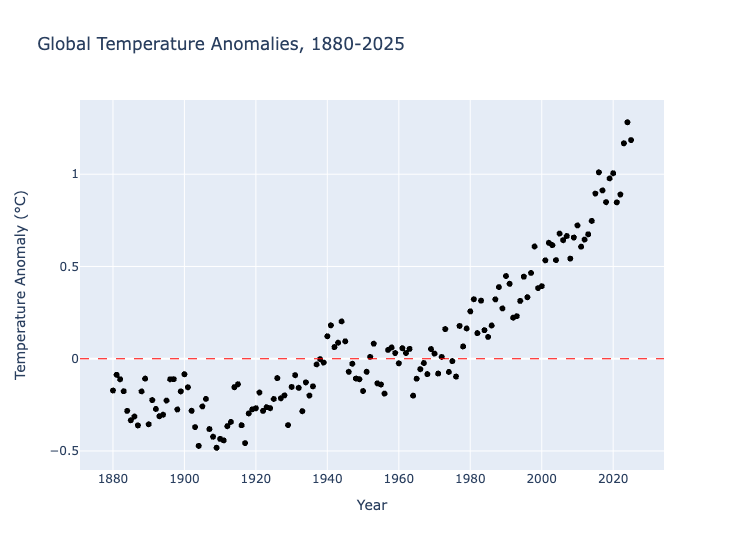

In [116]:
fig = px.scatter(temps, x = "Year", y = "Temp_Anomaly",
                 title = "Global Temperature Anomalies, 1880-2025",
                 labels = {"Temp_Anomaly": "Temperature Anomaly (°C)"},
                 color_discrete_sequence = ["black"],
                 height = 550)

fig.add_hline(y = 0, line_width = 1, line_dash = "dash", line_color = "red")

**What do we see?**

* There is a clear **positive trend**: anomalies tend to increase with year.
* The trend is not perfectly straight: the planet cooled slightly or stayed flat in the early 1900s, and the climb is steeper in recent decades.
* The points don't fall *exactly* on any curve. There's year-to-year "wiggle" around the overall trend.

Now suppose someone asks:

> **What temperature anomaly should we expect in the year 2030?**

We don't have data for 2030, so we need to make a **prediction**. How might we do it?

---
---

## A First Prediction Method: k-Nearest Neighbours

### The Idea

Here's a natural way to make a prediction: *look at what happened in similar situations.*

* If you want to guess what the weather will be like tomorrow, you might think back to *similar* days.
* If you want to guess how much a house will sell for, you'd look at what *similar* houses sold for.

That's the entire idea behind **k-nearest neighbours (k-NN)**:

> To predict the response for a new unit, find the $k$ units in our data whose explanatory variable values are *closest* to the new unit's. Then **average their responses**.

Those $k$ closest units are the new unit's **nearest neighbours**, and $k$ is a number *we* choose.

For our temperature data, "closest" translates to the years nearest (i.e., the ones with the smallest *distance* from) the year we care about.

### k-NN by Hand: Predicting 2030

Let's carry out k-NN by hand with $k = 5$ for the year 2030.

**Step 1.** Measure the distance from 2030 to every year in the data.

In [117]:
new_year = 2030

by_hand = temps.copy()
by_hand["Distance"] = (by_hand["Year"] - new_year).abs()
by_hand.sort_values(by = "Distance").head(8)

,Year,Temp_Anomaly,Distance
145,2025,1.185000,5
144,2024,1.281667,6
143,2023,1.167500,7
142,2022,0.890000,8
141,2021,0.847500,9
140,2020,1.005000,10
139,2019,0.977500,11
138,2018,0.848333,12


**Step 2.** Keep the $k = 5$ closest years. These are the 5 nearest neighbours.

In [118]:
k = 5
neighbours = by_hand.sort_values(by = "Distance").head(k)
neighbours

,Year,Temp_Anomaly,Distance
145,2025,1.185000,5
144,2024,1.281667,6
143,2023,1.167500,7
142,2022,0.890000,8
141,2021,0.847500,9


**Step 3.** Average the responses of those neighbours. This average is our prediction.

In [119]:
neighbours["Temp_Anomaly"].mean()

1.0743333339999999

So, our 5-NN prediction for the 2030 temperature anomaly is about $1.07^\circ$C above the 1951-1980 average.

**That's the whole algorithm! Let's recap:**

| Step | What we do |
|:-:|---|
| 1 | Compute the **distance** from the new unit to every unit in the data. |
| 2 | Find the **$k$ nearest** units (the neighbours). |
| 3 | **Average** the neighbours' responses to get the prediction. |

---

### 🗣 ACTIVITY: Does the choice of $k$ matter?

With a partner, discuss:

1. We predicted 2030 using $k = 5$, which averages the anomalies from 2021-2025. What would the prediction be if $k = 1$? Which years would be averaged if $k = 20$?
2. Which would you expect to give a *larger* prediction for 2030, $k = 1$ or $k = 20$? (*Hint:* look back at the scatter plot. What are anomalies doing near the right edge?)
3. Is there an obviously "correct" choice for $k$?

---
---

## 💻 Interactive: Build Your Intuition for k-NN

Before we ask Python to do this for us, let's play with the idea. The app below lets you see how k-NN makes predictions and what happens when you change $k$.

> **If the app doesn't display below**, open it in its own browser tab: [https://nathaniel-t-stevens.shinyapps.io/knn_prediction_app/](https://nathaniel-t-stevens.shinyapps.io/knn_prediction_app/)

In [120]:
%%html
<div style="text-align: center;">
<iframe src="https://nathaniel-t-stevens.shinyapps.io/knn_prediction_app/" width="100%" height="850" frameborder="0"></iframe>
</div>

**Explore the app:**

1. Set $k$ to its **smallest** value. What does the resulting prediction curve look like? How closely does it follow every individual data point?
2. Now set $k$ to its **largest** value. What happens to the prediction curve? What is it ignoring?
3. Somewhere in between, find a value of $k$ that you think gives a *sensible* summary of the pattern in the data. What did you look for to decide?
4. What do you think the prediction would be *outside* the range of the data (e.g., to the right of the last data point)? Why?

**Key ideas to take away from the app:**

* **Small $k$**: each prediction is based on very few neighbours, so the prediction curve is *wiggly* and chases every data point, including the random year-to-year noise.
* **Large $k$**: each prediction averages over many neighbours, so the prediction curve is *smooth*, perhaps too smooth to capture real features of the pattern.
* $k$ is a **knob** that the data scientist turns. Different knob settings give different predictions!

---
---

## k-NN with `scikit-learn`

Doing k-NN by hand is instructive but slow. Fortunately, there's a Python library that does it for us (and so much more): `scikit-learn` (imported as `sklearn`).

`scikit-learn` is *the* most widely used Python library for machine learning. A convenient feature of the library is that nearly every method follows the **same three-step recipe**:

| Step | What it does | Code |
|---|---|---|
| **1. Create** the model | Choose a method and its settings (e.g., the value of $k$). | `model = KNeighborsRegressor(n_neighbors = 5)` |
| **2. Fit** the model | Show the model the data so that it can "learn" from it. | `model.fit(X, y)` |
| **3. Predict** | Ask the model for predictions at new explanatory variable values. | `model.predict(new_X)` |

This *create-fit-predict* recipe will be the *same* for every model we encounter; only step 1 will change from one model to another.

### Step 0: Separate the explanatory variable(s) from the response

`scikit-learn` expects the data in two pieces:

* `X`: the explanatory variable(s). This must be a **data frame**, even if there's only one explanatory variable.
* `y`: the response variable. This is a **series**.

Recall from the EDA lecture that single brackets `[]` give a *series*, and double brackets `[[]]` give a *data frame*. That's why `X` uses *double* brackets below:

In [121]:
X = temps[["Year"]]         
y = temps["Temp_Anomaly"]   

### Step 1: Create the model

The k-NN method for numeric prediction lives in `sklearn.neighbors` and is called `KNeighborsRegressor`. The value of $k$ is set with the `n_neighbors` argument.

In [122]:
from sklearn.neighbors import KNeighborsRegressor

knn5 = KNeighborsRegressor(n_neighbors = 5)

### Step 2: Fit the model

For k-NN, "fitting" simply means storing the data so the model can look up neighbours later.

In [123]:
knn5.fit(X, y)

KNeighborsRegressor()

### Step 3: Predict

Let's determine the 2030 prediction. The new values must also be supplied as a data frame with the *same column name* (i.e., `Year`) as `X`.

In [124]:
new_data = pd.DataFrame({"Year": [2030]})
knn5.predict(new_data)

array([1.07433333])

This matches the prediction we computed by hand!

We can ask for several predictions at once by supplying several years:

In [125]:
new_data = pd.DataFrame({"Year": [1950, 1998, 2030, 2050]})
knn5.predict(new_data)

array([-0.09083332,  0.4365    ,  1.07433333,  1.07433333])

---
---

## The Prediction Curve and the Effect of $k$

To see the entire model at a glance, we can ask for predictions at *every* year from 1880 to 2030 and then connect the dots. This gives the model's **prediction curve**.

Below we do this for four values of $k$.

In [126]:
# A grid of years at which to make predictions
year_grid = pd.DataFrame({"Year": np.arange(1880, 2031)})

# Fit k-NN for several values of k and store each model's prediction curve
curves = []
for k in [1, 5, 15, 50]:
    model = KNeighborsRegressor(n_neighbors = k).fit(X, y)
    curve = year_grid.copy()
    curve["Prediction"] = model.predict(year_grid)
    curve["k"] = k
    curves.append(curve)

curves = pd.concat(curves)
curves.head()

,Year,Prediction,k
0,1880,-0.172500,1
1,1881,-0.087500,1
2,1882,-0.111667,1
3,1883,-0.175833,1
4,1884,-0.282500,1


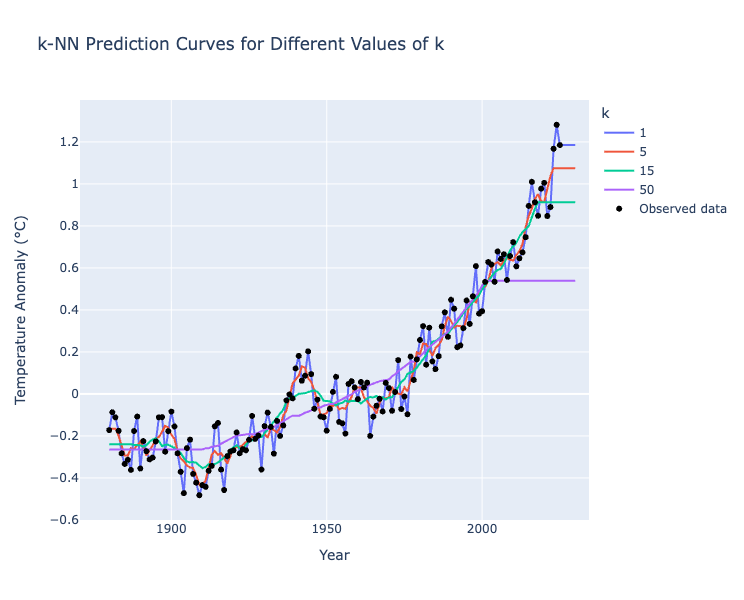

In [127]:
fig = px.line(curves, x = "Year", y = "Prediction", color = "k",
              title = "k-NN Prediction Curves for Different Values of k",
              labels = {"Prediction": "Temperature Anomaly (°C)"},
              height = 600)

# Add the observed data
fig.add_scatter(x = temps["Year"], y = temps["Temp_Anomaly"], mode = "markers",
                name = "Observed data", marker_color = "black")

**What do we see?**

* $k = 1$ (the "connect-the-dots" curve): passes through every single data point, following every little *wiggle*.
* $k = 5$ and $k = 15$: progressively smoother. They capture the overall upward trend but smooth over the year-to-year noise.
* $k = 50$: very smooth, but now it's too *stiff*: it smooths right over the early-1900s dip and the steep recent rise.
* Look at the right edge, past 2025. Every curve goes flat...

---

#### ACTIVITY 💻: Make predictions for 1990 and 2030 using $k = 3$ and $k = 25$.

<details>
<summary><b>Show Solution</b></summary>

```python
new_data = pd.DataFrame({"Year": [1990, 2030]})

knn3 = KNeighborsRegressor(n_neighbors = 3).fit(X, y)
knn25 = KNeighborsRegressor(n_neighbors = 25).fit(X, y)

print("k = 3: ", knn3.predict(new_data))
print("k = 25:", knn25.predict(new_data))
```

</details>

---
---

## How Well Does the Model Predict?

We've seen that different values of $k$ give different predictions. How do we decide which is better? We need a way to **measure prediction performance**.

The natural approach: for each year in our data, compare the model's prediction to what *actually* happened.

### Residuals

For each unit $i$, let

* $y_i$ be the **observed** response (the actual anomaly), and
* $\hat{y}_i$ ("y-hat") be the **predicted** response (what the model says it should be).

The **residual** is the *prediction error*, the gap between observed and predicted:

$$e_i = y_i - \hat{y}_i$$

* A **positive** residual means the model **under-predicted** (reality was higher).
* A **negative** residual means the model **over-predicted** (reality was lower).
* A residual of **zero** means a perfect prediction.

Let's compute the residuals for the $k = 15$ model. First we get the model's prediction for every year in our data:

In [128]:
knn15 = KNeighborsRegressor(n_neighbors = 15).fit(X, y)

temps["Predicted"] = knn15.predict(X)
temps["Residual"] = temps["Temp_Anomaly"] - temps["Predicted"]
temps

,Year,Temp_Anomaly,Predicted,Residual
0,1880,-0.172500,-0.239278,0.066778
1,1881,-0.087500,-0.239278,0.151778
2,1882,-0.111667,-0.239278,0.127611
3,1883,-0.175833,-0.239278,0.063444
4,1884,-0.282500,-0.239278,-0.043222
...,...,...,...,...
141,2021,0.847500,0.912944,-0.065444
142,2022,0.890000,0.912944,-0.022944
143,2023,1.167500,0.912944,0.254556
144,2024,1.281667,0.912944,0.368722


Each row now has the observed anomaly, the model's predicted anomaly, and the residual. Let's look at a few specific years:

In [129]:
temps[temps["Year"].isin([1910, 1945, 1980, 2015])]

,Year,Temp_Anomaly,Predicted,Residual
30,1910,-0.434167,-0.353333,-0.080833
65,1945,0.094167,0.011556,0.082611
100,1980,0.256667,0.146444,0.110222
135,2015,0.895000,0.798778,0.096222


Residuals have a nice visual interpretation: the **vertical distance** between each data point and the prediction curve. In the plot below, each gray segment is a residual.

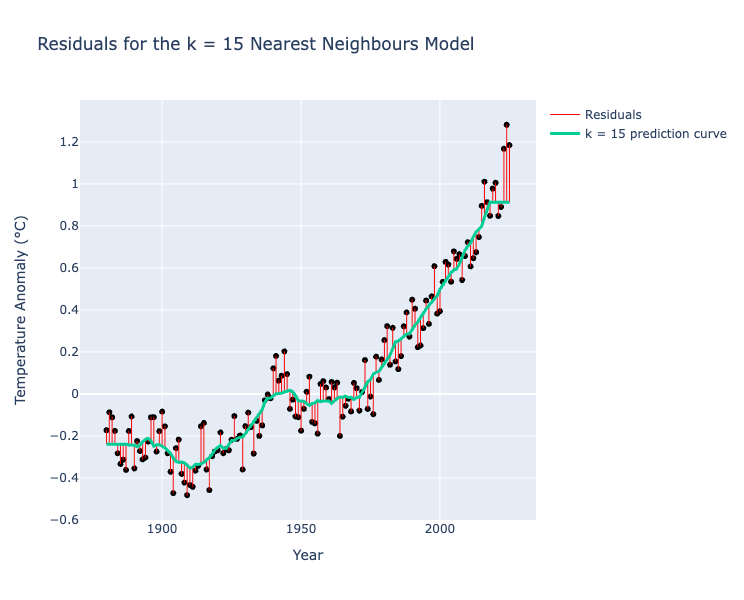

In [143]:
# Build the vertical segments (None separates one segment from the next)
seg_x, seg_y = [], []
for year, obs, pred in zip(temps["Year"], temps["Temp_Anomaly"], temps["Predicted"]):
    seg_x += [year, year, None]
    seg_y += [obs, pred, None]

fig = px.scatter(temps, x = "Year", y = "Temp_Anomaly",
                 title = "Residuals for the k = 15 Nearest Neighbours Model",
                 labels = {"Temp_Anomaly": "Temperature Anomaly (°C)"},
                 color_discrete_sequence = ["black"],
                 height = 600)

fig.add_scatter(x = seg_x, y = seg_y, mode = "lines", name = "Residuals",
                line = dict(color = "red", width = 1))

fig.add_scatter(x = temps["Year"], y = temps["Predicted"], mode = "lines", name = "k = 15 prediction curve",
                line = dict(color = "#00CC96", width = 3))

fig.data[0].name = "Observed data"
fig.update_layout(showlegend = True)

---
---

## One Number to Summarize Performance

There's one residual for every year, so 146 numbers. We want summarize them with a **single number** that conveys how well the model predicts. It needs to be *large* when the residuals are large and *small* when they're small.

The most obvious idea is to take their average. But look at what happens with a terrible model, one that predicts the *same* value, the overall average anomaly, for every single year:

In [131]:
terrible_prediction = temps["Temp_Anomaly"].mean()
terrible_residuals = temps["Temp_Anomaly"] - terrible_prediction

terrible_residuals.sum()

3.552713678800501e-15

The average is (essentially) **zero**, suggesting the model is perfect! The model is of course not perfect. What's happened is that positive and negative residuals have **cancelled each other out**. The raw sum can't distinguish a good model from a terrible one.

We need to prevent cancellation by making every residual *positive* before adding. There are two classic ways:

### Fix 1: Mean Squared Error (MSE)

Square each residual (squares are never negative), then take their average:

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} e_i^2 = \frac{e_1^2 + e_2^2 + \cdots + e_n^2}{n}$$

### Fix 2: Mean Absolute Error (MAE)

Take the absolute value of each residual (which strips the sign), then take their average:

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} \frac{|e_i| = |e_1| + |e_2| + \cdots + |e_n|}{n}$$

**For both, smaller is better.** A model that predicted every observation perfectly would have MSE = MAE = 0.

Let's compute both for our $k = 15$ model:

In [132]:
temps["Squared Residual"] = temps["Residual"] ** 2
temps["Absolute Residual"] = temps["Residual"].abs()

temps[temps["Year"].isin([1910, 1945, 1980, 2015])]

,Year,Temp_Anomaly,Predicted,Residual,Squared Residual,Absolute Residual
30,1910,-0.434167,-0.353333,-0.080833,0.006534,0.080833
65,1945,0.094167,0.011556,0.082611,0.006825,0.082611
100,1980,0.256667,0.146444,0.110222,0.012149,0.110222
135,2015,0.895000,0.798778,0.096222,0.009259,0.096222


In [146]:
MSE = temps["Squared Residual"].mean()
MAE = temps["Absolute Residual"].mean()

print(f"Mean squared error (MSE):  {MSE}")
print(f"Mean absolute error (MAE): {MAE}")

Mean squared error (MSE):  0.010359668730158126
Mean absolute error (MAE): 0.083464611456621


**A note on units:** the MAE is in the same units as the response ($^\circ$C), which makes it easy to interpret. The MSE is in *squared* units ($^\circ$C$^2$), which is harder to interpret but, as we'll see next lecture, has other advantages.

---

#### ACTIVITY 💻: Calculate the MSE and MAE for the $k = 3$ nearest neighbours model.

<details>
<summary><b>Show Solution</b></summary>

```python
knn3 = KNeighborsRegressor(n_neighbors = 3).fit(X, y)
residuals_3 = y - knn3.predict(X)

print(f"MSE: {(residuals_3 ** 2).mean()}")
print(f"MAE: {residuals_3.abs().mean()}")
```

</details>

---
---

## Comparing Values of $k$

Now we can answer our earlier question: *which value of $k$ predicts best?* Let's compute MSE and MAE for a range of $k$ values.

In [148]:
results = []
for k in [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]:
    model = KNeighborsRegressor(n_neighbors = k).fit(X, y)
    residuals = y - model.predict(X)
    results.append({"k": k,
                    "MSE": (residuals ** 2).mean(),
                    "MAE": residuals.abs().mean()})

results = pd.DataFrame(results)
results

,k,MSE,MAE
0,1,0.000000,0.000000
1,2,0.003140,0.046570
2,3,0.003307,0.047481
3,5,0.006338,0.066715
4,10,0.008696,0.077726
5,15,0.010360,0.083465
6,20,0.012000,0.087834
7,30,0.016621,0.099287
8,50,0.029660,0.122317
9,100,0.079318,0.197948


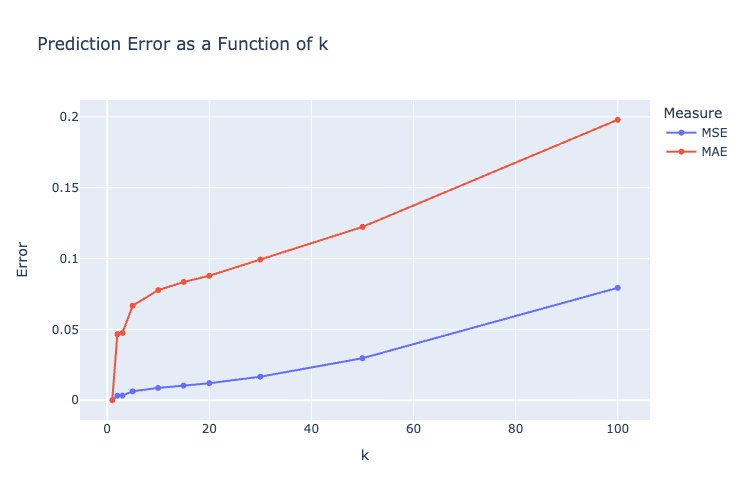

In [150]:
fig = px.line(results, x = "k", y = ["MSE", "MAE"], markers = True,
              title = "Prediction Error as a Function of k",
              labels = {"value": "Error", "variable": "Measure"},
              height = 500)
fig

**What do we see?**

* $k = 1$ has MSE = MAE = 0. **A perfect score!** Why? When we ask the model to predict a year that is *in the data*, that year's own observation is its own nearest neighbour. With $k = 1$, the model just reads off the answer.
* As $k$ increases, **both MSE and MAE increase**. Averaging over more neighbours pulls predictions away from each year's individual value.

By these measures the "best" model is the one with $k = 1$: the model that memorizes the data. That should make you a little suspicious. Is a model that has simply memorized the data really a *good predictor*? Keep that question in mind.

> For now, we have a precise language for describing *how well a model fits the data we have*: **residuals, MSE and MAE**. We'll use it extensively in the coming lectures.

---
---

## Limitations of k-NN and a Segue to Linear Regression

Earlier we noticed that every prediction curve goes **flat** to the right of 2025. Let's look at what $k$-NN predicts for 2030 for various values of $k$:

In [136]:
new_data = pd.DataFrame({"Year": [2030]})

for k in [1, 5, 15, 50]:
    model = KNeighborsRegressor(n_neighbors = k).fit(X, y)
    print(f"k = {k:>2}: predicted 2030 anomaly = {model.predict(new_data)[0]:.3f}")

k =  1: predicted 2030 anomaly = 1.185
k =  5: predicted 2030 anomaly = 1.074
k = 15: predicted 2030 anomaly = 0.913
k = 50: predicted 2030 anomaly = 0.539


Two things stand out:

**1. The prediction depends heavily on $k$.** The $k = 1$ model predicts $1.19^\circ$C and the $k = 50$ model predicts $0.54^\circ$C. That's a big spread.

**2. $k$-NN can only predict values it has already seen.** Every prediction is an *average of past observations*. So, no matter how steep the recent upward trend, k-NN will never predict anything beyond the range of anomalies it has observed *near* the year in question. For years beyond the end of the data, the neighbours are always just the *most recent* years, which is why the curves go flat. And the larger $k$ is, the further back in time those neighbours reach, and the *lower* the 2030 prediction becomes, even though temperatures have been rising!

k-NN also has to **carry around the entire data set** to make any prediction, and it doesn't give us a simple *summary* of the relationship, like *"how fast is the planet warming?"*

Look back at the scatter plot. Even though the points wiggle, the overall pattern looks *roughly like a straight line sloping upward*. What if, instead of averaging neighbours, we **assumed the pattern is a line** and used the data to find the *best* line?

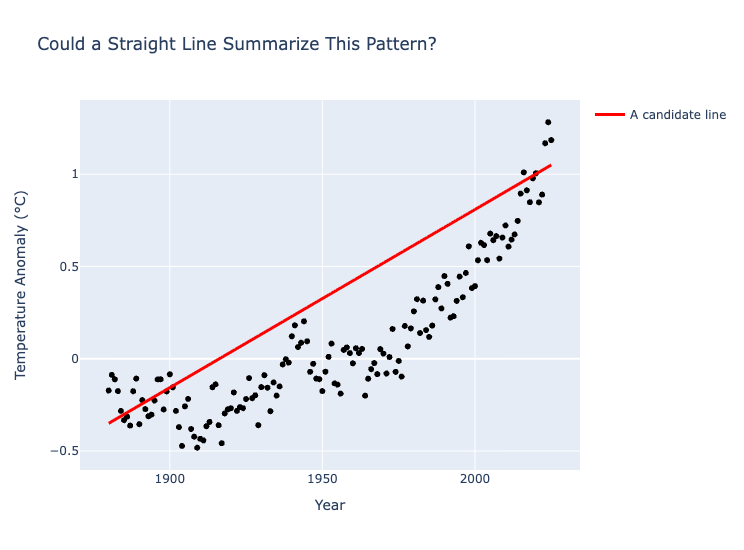

In [151]:
fig = px.scatter(temps, x = "Year", y = "Temp_Anomaly",
                 title = "Could a Straight Line Summarize This Pattern?",
                 labels = {"Temp_Anomaly": "Temperature Anomaly (°C)"},
                 color_discrete_sequence = ["black"],
                 height = 550)

# One (hand-picked, not necessarily good!) candidate line
fig.add_scatter(x = [1880, 2025], y = [-0.35, 1.05], mode = "lines", name = "A candidate line",
                line = dict(color = "red", width = 3))

fig.data[0].name = "Observed data"
fig.update_layout(showlegend = True)

A straight line is described by just **two numbers** (an intercept and a slope), so it's an extremely *compact* summary. The slope would directly tell us the *rate of warming*. And, because a line keeps on going, it will give predictions beyond the range of the data.

But many different lines could be drawn through these points. **How do we decide which line is best?** Some recent ideas (*residuals, MSE and MAE*) are going to give us the answer.

---

### 🗣 ACTIVITY: Draw a line

Take a minute to *draw* (on paper or in your head) the straight line you think best summarizes the scatter plot above.

1. How did you decide where to put it?
2. How could you convince a classmate that *your* line is better than theirs, using the tools we developed in this lecture?
3. Could you instruct a computer to find the best line? What would you have to tell it?

**This is exactly where we pick up next time: simple linear regression.**

---
---

## Summary of Useful Methods and Functions

| Code | What it does |
|---|---|
| `from sklearn.neighbors import KNeighborsRegressor` | Imports the k-NN method for numeric prediction. |
| `model = KNeighborsRegressor(n_neighbors = k)` | **Creates** a k-NN model that uses $k$ neighbours. |
| `model.fit(X, y)` | **Fits** the model to explanatory variables `X` (a data frame) and response `y` (a series). |
| `model.predict(new_X)` | **Predicts** the response for each row of `new_X` (a data frame with the same columns as `X`). |
| `y - model.predict(X)` | Computes the **residuals**. |
| `(residuals ** 2).mean()` | Computes the **mean squared error (MSE)**. |
| `residuals.abs().mean()` | Computes the **mean absolute error (MAE)**. |

---
---

## Key Takeaways

* **Prediction** is the *predictive* problem type from PPDAC: given what we know about a *new* unit ($x$), what should we expect for the response ($y$)? If $y$ is numeric the problem is called **regression** (numeric prediction); if $y$ is categorical, it's **classification**.
* Prediction is the foundation of **machine learning** and **AI**: algorithms learn patterns from examples in order to predict outcomes for new inputs.
* We studied **global temperature anomalies**, deviations from the 1951-1980 average. Anomalies tell us whether it's warmer or cooler than *usual*, and are far more comparable across places and times than raw temperatures.
* **k-nearest neighbours (k-NN)** predicts by finding the $k$ closest units in the data and **averaging** their responses.
* $k$ is a knob we turn: **small $k$** gives a wiggly curve that chases noise; **large $k$** gives a smooth, stiff curve.
* We measure prediction error with **residuals** $e_i = y_i - \hat{y}_i$. We summarize them with the **mean squared error** (MSE) or the **mean absolute error** (MAE). *Smaller is better.* Simply adding the raw residuals doesn't work because positive and negative ones cancel.
* k-NN is simple and flexible, but its predictions can't go beyond the values it has seen, it depends heavily on $k$, and it doesn't summarize the relationship. These limitations motivate **simple linear regression**, which we'll introduce next.

---
---